# mzML Plotting Comparison: pyOpenMS vs. pyteomics

This notebook demonstrates how to extract and plot a specific mass spectrum from an `mzML` file using two different libraries: **pyOpenMS** and **pyteomics**.

The goal is to ensure that both methods yield identical results by keeping their loading and extraction logic completely independent.

In [57]:
import matplotlib.pyplot as plt
import numpy as np
import pyopenms
from pyteomics import mzml as py_mzml

## Configuration
Set the path to your mzML file and the Target Spectrum ID (Native ID) you wish to plot.

In [58]:
# REPLACE THESE WITH YOUR ACTUAL FILE AND SPECTRUM ID
MZML_FILE_PATH = "/mnt/volume/nacho/data/ProCa_Anna/small_dataset/231204_DF_ProCa_ProT002_W6-32_20_LC005-2_MSV035_HT_Rep3_Slot1-21_1_330.mzML"
TARGET_SPECTRUM_ID =  "index=35947" #"controllerType=0 controllerNumber=1 scan=100" # Example format

## Method 1: pyOpenMS
This function loads the file using `pyopenms.MSExperiment` and iterates to find the spectrum with the matching native ID.

In [59]:
def get_data_pyopenms(file_path, target_id):
    """
    Independently loads an mzML file using pyOpenMS and extracts the spectrum.
    """
    print(f"[pyOpenMS] Loading {file_path}...")
    exp = pyopenms.MSExperiment()
    # Load the file fresh
    pyopenms.MzMLFile().load(file_path, exp)
    
    found_spec = None
    for spec in exp:
        if spec.getNativeID() == target_id:
            found_spec = spec
            break
            
    if found_spec is None:
        raise ValueError(f"Spectrum with ID '{target_id}' not found in file (pyOpenMS).")
    
    mz, intensity = found_spec.get_peaks()
    print(f"[pyOpenMS] Extracted {len(mz)} peaks.")
    return mz, intensity


## Method 2: pyteomics
This function loads the file using `pyteomics.mzml.read` and retrieves the spectrum by ID.

In [60]:
def get_data_pyteomics(file_path, target_id):
    """
    Independently loads an mzML file using pyteomics and extracts the spectrum.
    """
    print(f"[pyteomics] Loading {file_path}...")
    # Use pyteomics to read the file
    with py_mzml.read(file_path) as reader:
        try:
            spec = reader.get_by_id(target_id)
        except KeyError:
            # Fallback or error if ID format differs slightly, but standard get_by_id usually works with nativeID
            raise ValueError(f"Spectrum with ID '{target_id}' not found in file (pyteomics).")
        
        mz = spec['m/z array']
        intensity = spec['intensity array']
        
    print(f"[pyteomics] Extracted {len(mz)} peaks.")
    return mz, intensity


## Comparison & Plotting
Now we run both methods and compare the results numerically and visually.

[pyOpenMS] Loading /mnt/volume/nacho/data/ProCa_Anna/small_dataset/231204_DF_ProCa_ProT002_W6-32_20_LC005-2_MSV035_HT_Rep3_Slot1-21_1_330.mzML...
[pyOpenMS] Extracted 85 peaks.
[pyteomics] Loading /mnt/volume/nacho/data/ProCa_Anna/small_dataset/231204_DF_ProCa_ProT002_W6-32_20_LC005-2_MSV035_HT_Rep3_Slot1-21_1_330.mzML...
[pyteomics] Extracted 85 peaks.

--- Comparison Results ---
Peak counts match: 85
SUCCESS: m/z and intensity values match exactly (within tolerance).


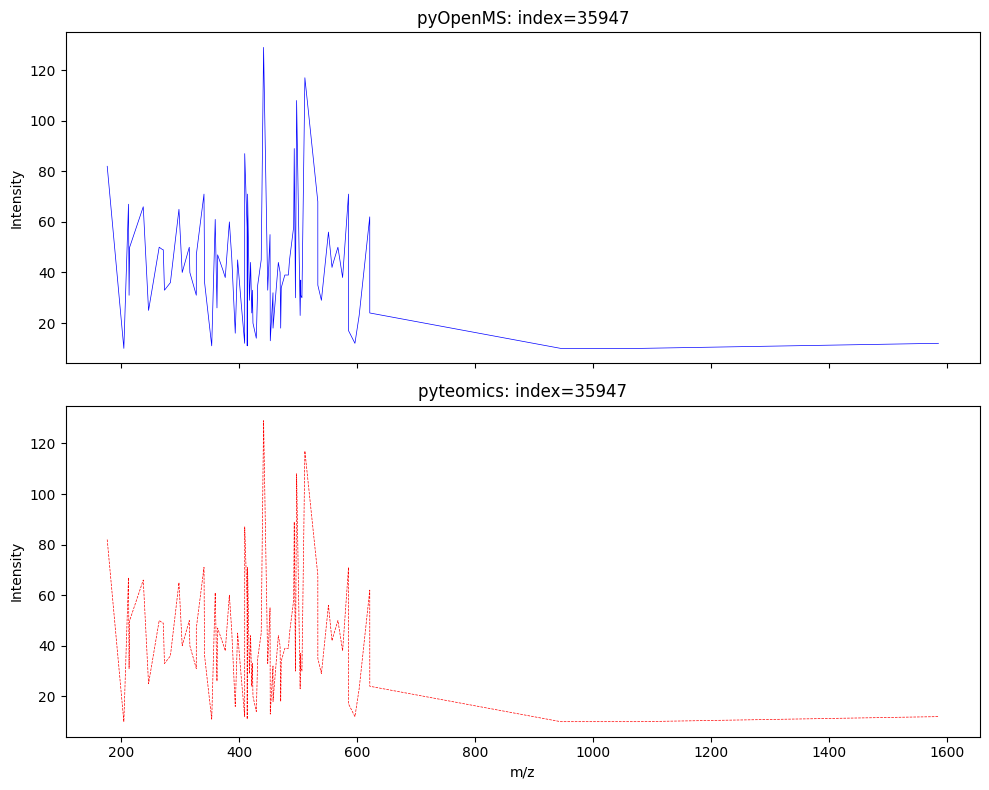

In [61]:
try:
    # 1. Run pyOpenMS Extraction
    mz_openms, int_openms = get_data_pyopenms(MZML_FILE_PATH, TARGET_SPECTRUM_ID)
    
    # 2. Run pyteomics Extraction
    mz_pyteomics, int_pyteomics = get_data_pyteomics(MZML_FILE_PATH, TARGET_SPECTRUM_ID)
    
    # 3. Numerical Comparison
    print("\n--- Comparison Results ---")
    
    # Check lengths
    if len(mz_openms) != len(mz_pyteomics):
        print(f"WARNING: Peak counts differ! OpenMS: {len(mz_openms)}, Pyteomics: {len(mz_pyteomics)}")
    else:
        print(f"Peak counts match: {len(mz_openms)}")
        
        # Check values
        mz_match = np.allclose(mz_openms, mz_pyteomics, atol=1e-5)
        int_match = np.allclose(int_openms, int_pyteomics, atol=1e-5)
        
        if mz_match and int_match:
            print("SUCCESS: m/z and intensity values match exactly (within tolerance).")
        else:
            print(f"WARNING: Values mismatch. m/z match: {mz_match}, intensity match: {int_match}")
            
    # 4. Plotting
    fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
    
    # Plot OpenMS
    ax[0].plot(mz_openms, int_openms, color='blue', linewidth=0.5)
    ax[0].set_title(f"pyOpenMS: {TARGET_SPECTRUM_ID}")
    ax[0].set_ylabel("Intensity")
    
    # Plot Pyteomics
    ax[1].plot(mz_pyteomics, int_pyteomics, color='red', linewidth=0.5, linestyle='--')
    ax[1].set_title(f"pyteomics: {TARGET_SPECTRUM_ID}")
    ax[1].set_xlabel("m/z")
    ax[1].set_ylabel("Intensity")
    
    plt.tight_layout()
    plt.show()

except Exception as e:
    print(f"An error occurred during execution: {e}")
